# 03 · Verify the preserved patient folds

Use the original five patient groups for every clean comparator. Reproduce the original fold-support table and balance figure without creating replacement splits.

Read the stages in numerical order. Training uses separate, explicitly invoked runners; executing this notebook only loads development data and saved artifacts.

Original notebooks, images, checkpoints and results remain available. The reserved test is outside this workflow.

**Original methods and figure reference:** [03_patient_splitting.ipynb](../Subset/03_patient_splitting.ipynb). Read [method coverage](METHOD_COVERAGE.md) for retained methods and declared adaptations.

## Load the frozen clean development dataset

In [1]:
NOTEBOOK_STAGE = '03_patient_fold_verification'
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from melanoma_detection.development_dataset import load_development_dataset, load_preserved_inner_memberships
from melanoma_detection.dedup_workflow import load_context, latest_evaluation, load_clean_scores, load_image_report, load_uncertainty_report, read_json, project_path, DIRECTORY, METADATA_SUITE, UNCERTAINTY
get_ipython().run_line_magic("matplotlib", "inline")
MANIFEST = "data/subset/processed/dedup_v1/dataset_manifest.json"
data, dataset_identity = load_development_dataset(ROOT, dataset_manifest=MANIFEST)
context = load_context(ROOT)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
FIGURE_DIR = ROOT / DIRECTORY / "figures" / NOTEBOOK_STAGE
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(figure, filename):
    if not filename or Path(filename).name != filename:
        raise ValueError("Figure name must be a simple stem.")
    figure.savefig(FIGURE_DIR / (filename + ".png"), dpi=180, bbox_inches="tight")
    figure.savefig(FIGURE_DIR / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(figure)

_score_bundle = None
def score_bundle():
    global _score_bundle
    if _score_bundle is None:
        _score_bundle = load_clean_scores(ROOT)
    return _score_bundle
display(pd.DataFrame([{"Images": len(data), "Malignant images": int(data.target.sum()),
    "Patients": data.patient_id.nunique(), "Malignant patients": data.loc[data.target.eq(1), "patient_id"].nunique()}]))
display(Markdown("**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training."))

def show_saved_table(relative, limit=30):
    path = project_path(ROOT, relative)
    if not path.exists():
        display(Markdown("**Pending:** " + relative + ". No results are inferred from unfinished runs."))
        return pd.DataFrame()
    table = pd.read_csv(path)
    display(table.head(limit))
    if len(table) > limit:
        display(Markdown(f"Showing {limit} of {len(table)} rows; the complete CSV is saved."))
    return table

def comparison_table():
    evaluation = latest_evaluation(ROOT)
    if "output_directory" not in evaluation:
        display(Markdown("**Pending:** clean evaluation has not been generated."))
        return pd.DataFrame()
    path = project_path(ROOT, evaluation["output_directory"] + "/model_comparison.csv")
    return pd.read_csv(path)

def model_chart(table, title):
    if table.empty:
        display(Markdown("**Pending:** no verified scores are available for this stage."))
        return
    table = table.sort_values("average_precision")
    fig, ax = plt.subplots(figsize=(9, max(3.2, .38 * len(table) + 1.5)), layout="constrained")
    ax.barh(table.model, table.average_precision, color="#276b91")
    ax.set(title=title, xlabel="Unweighted mean outer-fold average precision", xlim=(0, max(.1, float(table.average_precision.max()) * 1.25)))
    finish_figure(fig, "model_comparison_ap")

def pilot_report(run_id):
    directory = ROOT / "results/image_d1_runs" / run_id
    path = directory / "summary.json"
    summary = read_json(path) if path.exists() else {"status": "pending"}
    if summary.get("status") == "complete":
        manifest = read_json(directory / "run_manifest.json")
        if manifest["dataset_identity"] != dataset_identity:
            raise ValueError("Pilot belongs to another dataset.")
        from melanoma_detection.development_dataset import sha256_file
        for relative, digest in summary["artifact_sha256"].items():
            artifact = (directory / relative).resolve()
            if not artifact.is_relative_to(directory.resolve()) or sha256_file(artifact) != digest:
                raise ValueError("Completed pilot artifact changed.")
    return directory, summary


,Images,Malignant images,Patients,Malignant patients
0,6706,127,422,88


**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training.

## 1. Explain the outer evaluation

For outer fold k, fit on patients in the other four groups and predict each image in k once. Patient ID is a grouping key, never an input feature. Fold numbers identify groups, not risk. Filtering removes images within a fold, so original patient memberships are retained even if image prevalence changes slightly.

In [2]:
original = pd.read_csv(ROOT / context["manifest"]["original_source"]["path"])
before = original.set_index("image_name")
assert original.image_name.is_unique and data.image_name.is_unique
assert np.array_equal(before.loc[data.image_name,"patient_id"].to_numpy(),data.patient_id.to_numpy())
assert np.array_equal(before.loc[data.image_name,"fold"].to_numpy(),data.fold.to_numpy())
assert set(original.patient_id) == set(data.patient_id)
display(pd.DataFrame([{"original_patients":original.patient_id.nunique(), "retained_patients":data.patient_id.nunique(),
    "changed_patient_memberships":0,"split_regenerated":False}]))

,original_patients,retained_patients,changed_patient_memberships,split_regenerated
0,422,422,0,False


## 2. Read before-and-after fold support

Check images, malignant images, patients and malignant patients together. Similar image prevalence does not imply similar patient-level prevalence. Preserve all groups rather than rebalancing after filtering; rebalancing would confound dataset and partition changes.

In [3]:
display(context["fold_counts"])
fold_table = data.groupby("fold").target.agg(images="size",malignant_images="sum",image_rate="mean")
patient = data.groupby(["fold","patient_id"]).target.max().reset_index()
fold_table = fold_table.join(patient.groupby("fold").target.agg(patients="size",malignant_patients="sum",patient_rate="mean"))
display(fold_table)

,fold,images_before,malignant_images_before,patients_before,images_after,malignant_images_after,patients_after,excluded_images,excluded_malignant
0,0,1370,25,84,1344,24,84,26,1
1,1,1372,26,84,1366,26,84,6,0
2,2,1381,26,87,1328,26,87,53,0
3,3,1371,25,82,1371,25,82,0,0
4,4,1370,26,85,1297,26,85,73,0


,images,malignant_images,image_rate,patients,malignant_patients,patient_rate
fold,,,,,,
0,1344,24,0.017857,84,17,0.202381
1,1366,26,0.019034,84,15,0.178571
2,1328,26,0.019578,87,21,0.241379
3,1371,25,0.018235,82,18,0.219512
4,1297,26,0.020046,85,17,0.200000


## 3. Recreate the fold-balance figure

The first panel applies the original plot's method: malignant image fraction by fold with a dashed overall image fraction. The second adds malignant-patient support. Neither plot is used to choose or revise folds.

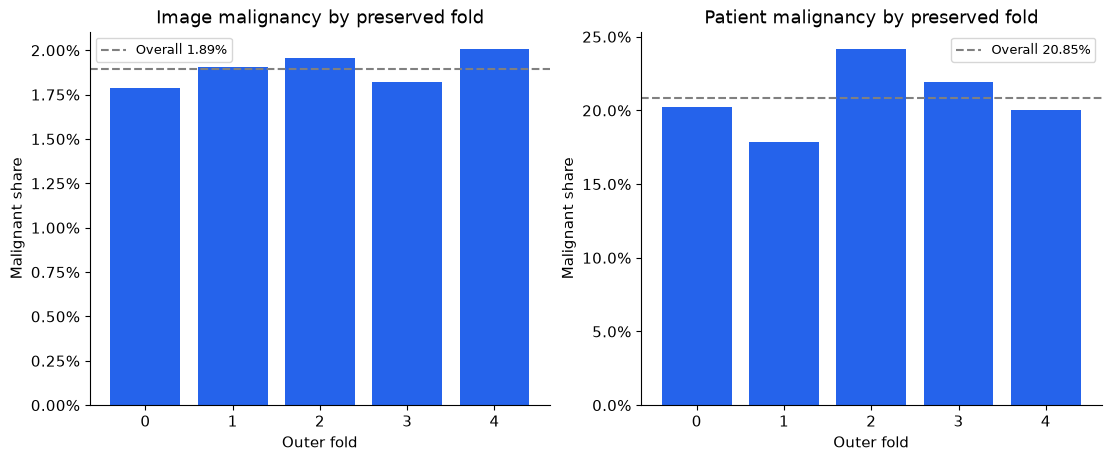

In [4]:
from matplotlib.ticker import PercentFormatter
fig,axes = plt.subplots(1,2,figsize=(11,4.5),layout="constrained")
for ax,column,overall,title in [(axes[0],"image_rate",data.target.mean(),"Image malignancy by preserved fold"),
    (axes[1],"patient_rate",patient.target.mean(),"Patient malignancy by preserved fold")]:
    ax.bar(fold_table.index,fold_table[column],color="#2563eb")
    ax.axhline(overall,color="grey",ls="--",label=f"Overall {overall:.2%}")
    ax.set(title=title,xlabel="Outer fold",ylabel="Malignant share",xticks=range(5)); ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.legend(fontsize=9)
finish_figure(fig,"patient_fold_balance")

## 4. Verify outer fitting and held-out disjointness

Every retained patient belongs to exactly one outer fold, every fold contains both classes and fitting/held-out patient overlap must be zero. These checks use only the frozen development records. The reserved-test separation check from the original notebook is deliberately not rerun under the current no-test-access boundary.

In [5]:
assert set(data.fold.unique()) == set(range(5))
assert data.groupby("patient_id").fold.nunique().eq(1).all()
checks=[]
for fold in range(5):
    fit = data.loc[data.fold.ne(fold)]; held = data.loc[data.fold.eq(fold)]
    assert set(fit.patient_id).isdisjoint(set(held.patient_id))
    assert set(fit.image_name).isdisjoint(set(held.image_name))
    assert set(fit.target.unique()) == set(held.target.unique()) == {0,1}
    checks.append({"outer_fold":fold,"fitting_images":len(fit),"held_images":len(held),
        "fitting_patients":fit.patient_id.nunique(),"held_patients":held.patient_id.nunique(),"patient_overlap":0})
display(pd.DataFrame(checks))

,outer_fold,fitting_images,held_images,fitting_patients,held_patients,patient_overlap
0,0,5362,1344,338,84,0
1,1,5340,1366,338,84,0
2,2,5378,1328,335,87,0
3,3,5335,1371,340,82,0
4,4,5409,1297,337,85,0


## 5. Inspect the preserved image inner memberships

B0 recipe and duration choices use three inner folds inside each outer-training pool. Load their saved memberships instead of rerunning the splitter. Inner validation assesses candidate choices; the held-out outer fold assesses the complete selected procedure.

,outer_fold,inner_fold,held_images,held_patients,held_malignant_images,held_malignant_patients,patient_overlap
0,0,0,1834,113,33,18,0
1,0,1,1704,111,35,27,0
2,0,2,1824,114,35,26,0
3,1,0,1809,113,32,29,0
4,1,1,1703,111,34,20,0
5,1,2,1828,114,35,24,0
6,2,0,1821,111,33,17,0
7,2,1,1775,112,34,25,0
8,2,2,1782,112,34,25,0
9,3,0,1831,113,33,25,0


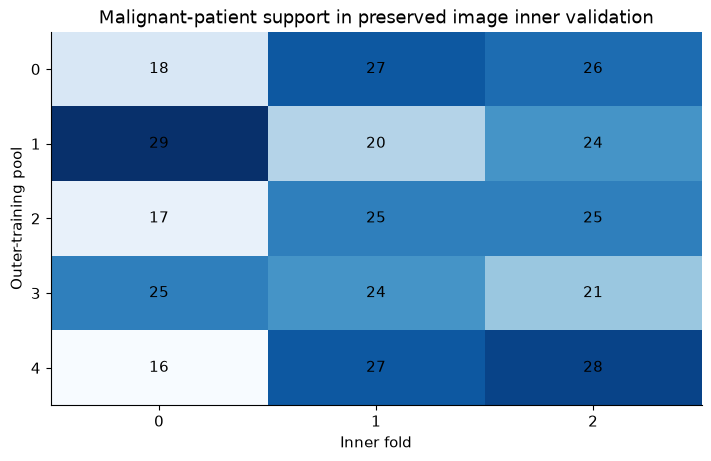

In [6]:
checks=[]
for outer in range(5):
    members=load_preserved_inner_memberships(ROOT,dataset_identity,outer)
    assert members.groupby("patient_id").inner_fold.nunique().eq(1).all()
    assert set(members.image_name) == set(data.loc[data.fold.ne(outer),"image_name"])
    for inner,held in members.groupby("inner_fold"):
        fitting=members.loc[members.inner_fold.ne(inner)]
        assert set(fitting.patient_id).isdisjoint(set(held.patient_id))
        checks.append({"outer_fold":outer,"inner_fold":int(inner),"held_images":len(held),
            "held_patients":held.patient_id.nunique(),"held_malignant_images":int(held.target.sum()),
            "held_malignant_patients":held.loc[held.target.eq(1),"patient_id"].nunique(),"patient_overlap":0})
display(pd.DataFrame(checks))
support=pd.DataFrame(checks).pivot(index="outer_fold",columns="inner_fold",values="held_malignant_patients")
fig,ax=plt.subplots(figsize=(7,4.5),layout="constrained")
ax.imshow(support,cmap="Blues",aspect="auto")
for row in range(5):
    for column in range(3): ax.text(column,row,str(support.iloc[row,column]),ha="center",va="center")
ax.set(title="Malignant-patient support in preserved image inner validation",xlabel="Inner fold",ylabel="Outer-training pool",xticks=range(3),yticks=range(5))
finish_figure(fig,"inner_malignant_patient_support")

## 6. Explain the metadata membership differences

The original metadata tuning uses seed 42 + outer_fold, while image selection uses its saved three-way patient memberships. Reconstruct metadata memberships from the original row order, then filter; the reconstruction is recorded because a historical membership receipt was not saved. The NN stopping fit uses a designated original outer fold inside the training pool. These internal memberships may differ while all models share the same outer-held-out records.

In [7]:
membership_receipt=read_json(ROOT / METADATA_SUITE / "memberships_receipt.json")
display(pd.DataFrame([membership_receipt]))
show_saved_table(METADATA_SUITE+"/inner_audit.csv",15)
show_saved_table("results/dedup_v1/metadata/epochs.csv",15)
display(Markdown("**Verified contract:** one common retained population, unchanged outer patient groups, preserved/reconstructed training-only inner memberships, and zero fitting/validation patient overlap. No splitter or reserved-test reader was called."))

,compatibility_sha256,status,historical_membership_receipt_available,reconstruction_source,versions,original_row_order_used,split_on_retained_rows,seed_rule,output_sha256
0,764a0bf22b45a8bd654119eaa9a15200e53c60096b1d44...,reconstructed_and_frozen,False,data/subset/processed/train_folds.csv,"{'python': '3.14.6', 'numpy': '2.5.2', 'pandas...",True,False,42 + outer_fold,{'results/dedup_v1/metadata_suite/metadata_ful...


,outer_fold,inner_fold,fit_images,validation_images,fit_patients,validation_patients,fit_positive_images,validation_positive_images,patient_overlap,outer_patient_overlap
0,0,0,3528,1834,225,113,70,33,0,0
1,0,1,3658,1704,227,111,68,35,0,0
2,0,2,3538,1824,224,114,68,35,0,0
3,1,0,3528,1812,225,113,66,35,0,0
4,1,1,3634,1706,225,113,69,32,0,0
5,1,2,3518,1822,226,112,67,34,0,0
6,2,0,3564,1814,226,109,67,34,0,0
7,2,1,3602,1776,224,111,68,33,0,0
8,2,2,3590,1788,220,115,67,34,0,0
9,3,0,3532,1803,226,114,68,34,0,0


,base_seed,outer_fold,training_seed,stop_fold,selected_epochs,stop_log_loss,attempted_stopping_epochs,outer_train_patients,score_patients,epoch_fit_patients,epoch_stop_patients,encoded_input_width
0,42,0,42,1,20,0.090664,32,338,84,254,84,10
1,142,0,142,2,18,0.092312,30,338,84,251,87,10
2,242,0,242,3,40,0.087399,52,338,84,256,82,10
3,42,1,43,2,59,0.091075,71,338,84,251,87,10
4,142,1,143,3,26,0.087991,38,338,84,256,82,10
5,242,1,243,4,12,0.095656,24,338,84,253,85,10
6,42,2,44,3,59,0.085894,71,335,87,253,82,10
7,142,2,144,4,12,0.097338,24,335,87,250,85,10
8,242,2,244,0,29,0.083573,41,335,87,251,84,10
9,42,3,45,4,11,0.097379,23,340,82,255,85,10


**Verified contract:** one common retained population, unchanged outer patient groups, preserved/reconstructed training-only inner memberships, and zero fitting/validation patient overlap. No splitter or reserved-test reader was called.

## Interpretation boundary

These are development results. Patient grouping protects separation between fitting and validation; bootstrap intervals condition on saved models. Sparse subgroups and selected inner-validation pilots cannot establish a final winner. No reserved-test conclusion is made.